# 02 - Modeling

**Workflow:** data -> split (80/20 stratified) -> **Pipeline + ColumnTransformer** (di `scripts/`) -> K-Fold CV -> training 4 metode -> evaluasi Macro F1 -> penyesuaian kelas -> model selection (Grid vs Random Search).

**Metode:** Regresi Logistik (`reglog`), Decision Tree (`tree`), SVM (`svm`), Analisis Diskriminan (`lda`), Random Forest (`rf`, pengembangan Decision Tree) dan Gradient Boosting (`hgb`).

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Root repo = satu level di atas folder notebooks/
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.append(str(ROOT))

from scripts.preprocess import load_data, split_xy, TARGET, ID_COL

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

import time, json
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from scripts.models import MODEL_BUILDERS
from scripts.evaluation import optimize_class_weights, honest_reweight_gain, get_scores, fit_gap

# PENGATURAN
SAMPLE_SIZE = None                                  # None = seluruh data train
CORE_METHODS = ["reglog", "tree", "svm", "lda"]     # 4 metode
EXTRA_METHODS = ["rf", "hgb"]                       # metode tambahan
RUN_CV = True                                       # K-Fold CV
CV_SIZE, CV_FOLDS = 40000, 5                        # subsampel & jumlah fold untuk CV
RUN_CURVES = True                                   # kurva validasi (underfit vs overfit)
CURVE_METHODS, CURVE_N = ["tree", "reglog"], 40000

## 1. Data dan split train/validasi

In [2]:
train, test, sample = load_data()
X, y = split_xy(train)
if SAMPLE_SIZE:
    X, _, y, _ = train_test_split(X, y, train_size=SAMPLE_SIZE, stratify=y, random_state=42)
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_tr.shape, "| validasi:", X_va.shape)

train: (426772, 15) | validasi: (106693, 15)


## 2. Pipeline dan ColumnTransformer

Semua preprocessing dibungkus dalam `Pipeline` + `ColumnTransformer` (`scripts/preprocess.py`) sehingga tidak ada data leakage:
1. `add_features`: umur 999 -> NaN + flag, fitur turunan, kolom silang kategorikal.
2. Numerik: `SimpleImputer(median)` + `StandardScaler` (untuk model berbasis jarak/gradien).
3. Kategorikal dan kode wilayah: `OneHotEncoder`; untuk model tertentu ditambah `TargetEncoder` (cross-fitting) dan fitur agregat wilayah.

Contoh pipeline reglog:

In [3]:
MODEL_BUILDERS["reglog"]()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('algo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...002CE625D5440>
,"inverse_func invers

## 3. K-Fold Cross Validation (Stratified)

Memberi estimasi performa yang lebih stabil daripada satu kali split, dengan simpangan baku antar-fold.

In [4]:
if RUN_CV:
    n = min(CV_SIZE, len(X_tr))
    if n < len(X_tr):
        Xc, _, yc, _ = train_test_split(X_tr, y_tr, train_size=n, stratify=y_tr, random_state=1)
    else:
        Xc, yc = X_tr, y_tr
    skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=42)
    rows = []
    for m in CORE_METHODS:
        t = time.time()
        sc = cross_val_score(MODEL_BUILDERS[m](), Xc, yc, cv=skf, scoring="f1_macro")
        rows.append({"metode": m, "cv_f1_macro": sc.mean(), "std": sc.std(), "detik": time.time() - t})
        print(f"{m:7s} CV Macro F1 = {sc.mean():.4f} +/- {sc.std():.4f}")
    display(pd.DataFrame(rows).round(4))

reglog  CV Macro F1 = 0.4898 +/- 0.0050
tree    CV Macro F1 = 0.4644 +/- 0.0035
svm     CV Macro F1 = 0.4869 +/- 0.0058
lda     CV Macro F1 = 0.4918 +/- 0.0021


,metode,cv_f1_macro,std,detik
0,reglog,0.4898,0.0050,164.1630
1,tree,0.4644,0.0035,33.3759
2,svm,0.4869,0.0058,213.3972
3,lda,0.4918,0.0021,18.8019


## 4. Training dan evaluasi pada data validasi

In [5]:
results, fitted, preds = {}, {}, {}
for m in CORE_METHODS + EXTRA_METHODS:
    t = time.time()
    model = MODEL_BUILDERS[m]()
    model.fit(X_tr, y_tr)
    preds[m] = model.predict(X_va)
    fitted[m] = model
    results[m] = {"macro_f1": f1_score(y_va, preds[m], average="macro"), "detik": time.time() - t}
    print(f"{m} | Macro F1 = {results[m]['macro_f1']:.4f} | {results[m]['detik']:.0f} detik")
    print(classification_report(y_va, preds[m], digits=3))
display(pd.DataFrame(results).T.round(4))

reglog | Macro F1 = 0.5166 | 400 detik
              precision    recall  f1-score   support

     Grade 1      0.550     0.753     0.636     11034
     Grade 2      0.328     0.395     0.358     12216
     Grade 3      0.397     0.394     0.395     19098
     Grade 4      0.494     0.483     0.488     25738
     Grade 5      0.769     0.652     0.705     38607

    accuracy                          0.546    106693
   macro avg      0.507     0.535     0.517    106693
weighted avg      0.563     0.546     0.551    106693

tree | Macro F1 = 0.5088 | 218 detik
              precision    recall  f1-score   support

     Grade 1      0.533     0.738     0.619     11034
     Grade 2      0.316     0.411     0.357     12216
     Grade 3      0.390     0.386     0.388     19098
     Grade 4      0.494     0.470     0.481     25738
     Grade 5      0.769     0.640     0.698     38607

    accuracy                          0.537    106693
   macro avg      0.500     0.529     0.509    106693
w

,macro_f1,detik
reglog,0.5166,399.5280
tree,0.5088,217.6506
svm,0.5088,795.0622
lda,0.5060,53.4594
rf,0.5395,109.2772
hgb,0.5483,262.5193


### Confusion matrix (dinormalisasi per kelas asli)

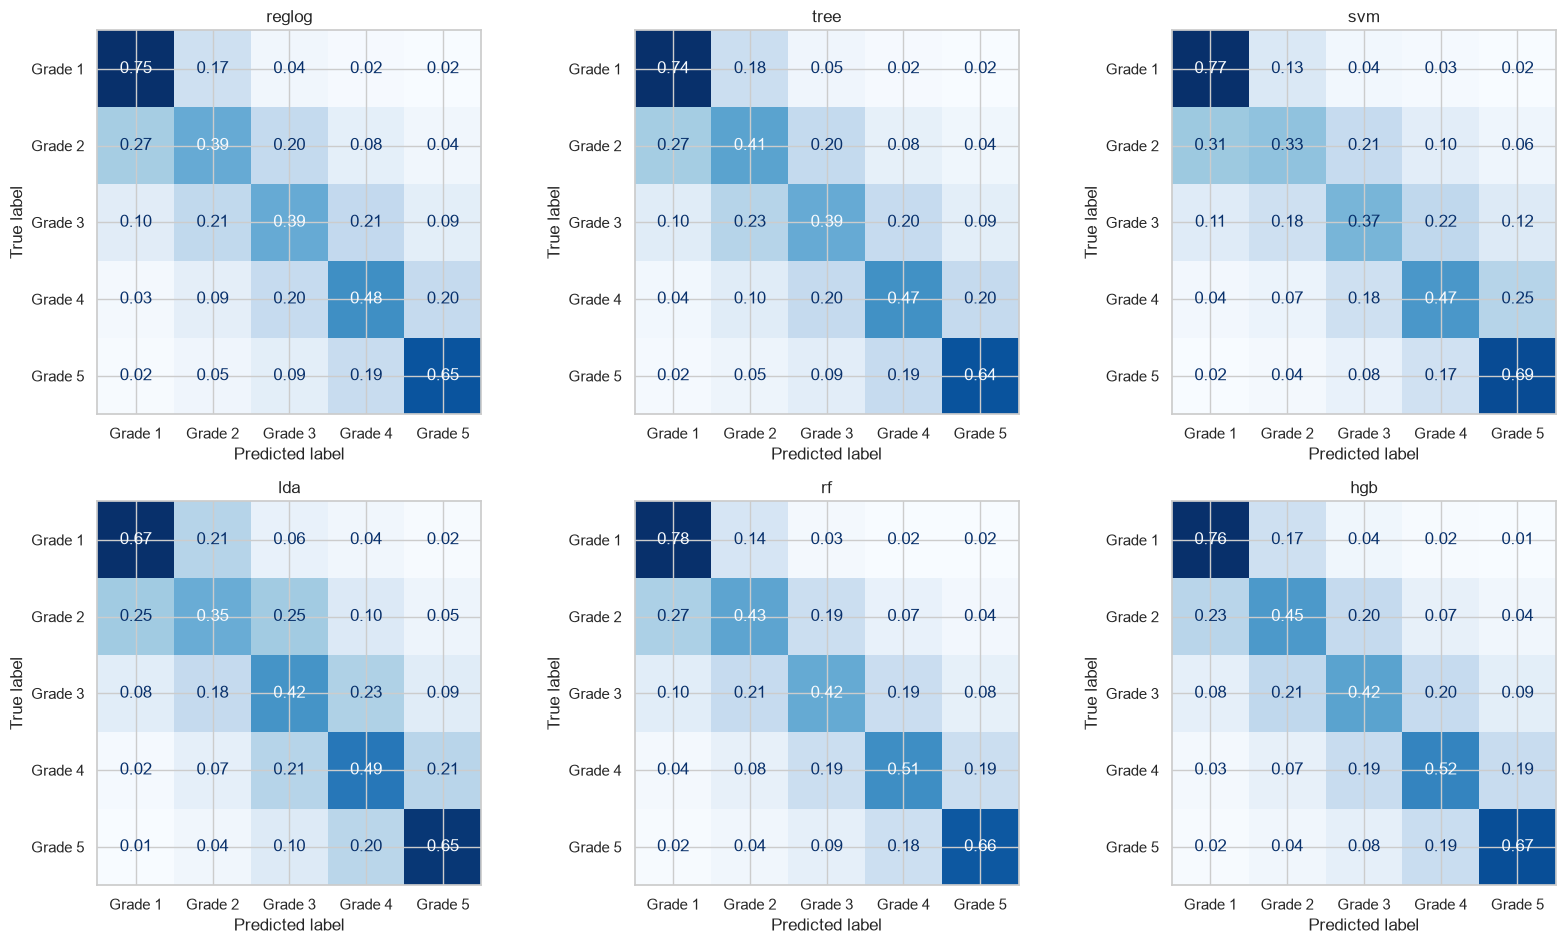

In [6]:
n = len(fitted)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.8 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, m in zip(axes, fitted):
    ConfusionMatrixDisplay.from_predictions(y_va, preds[m], normalize="true", ax=ax,
                                            cmap="Blues", colorbar=False, values_format=".2f")
    ax.set_title(m)
for ax in axes[n:]:
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix_all.png", dpi=130)
plt.show()

for m in fitted:
    f, a = plt.subplots(figsize=(5.5, 4.8))
    ConfusionMatrixDisplay.from_predictions(y_va, preds[m], normalize="true", ax=a,
                                            cmap="Blues", colorbar=False, values_format=".2f")
    a.set_title(f"Confusion matrix - {m}")
    f.tight_layout()
    f.savefig(FIG_DIR / f"confusion_matrix_{m}.png", dpi=130)
    plt.close(f)

## 5. Diagnosis overfitting / underfitting

Skor **train** dibandingkan dengan skor **validasi**:
- gap besar (train jauh di atas validasi) -> **overfit** (varians tinggi);
- train dan validasi sama-sama rendah dan berdekatan -> **underfit** (bias tinggi), terutama bila model yang lebih fleksibel jelas lebih baik;
- *Catatan:* pada model ber-TargetEncoder skor train sedikit terlalu optimistis, jadi gap adalah batas atas.

,train_f1,val_f1,gap,verdict
metode,,,,
reglog,0.5240,0.5166,0.0075,gap kecil (tidak overfit)
tree,0.5300,0.5088,0.0212,gap kecil (tidak overfit)
svm,0.5165,0.5088,0.0077,gap kecil (tidak overfit)
lda,0.5109,0.5060,0.0049,gap kecil (tidak overfit)
rf,0.5861,0.5395,0.0467,gap sedang
hgb,0.6485,0.5483,0.1002,indikasi overfit (gap besar)


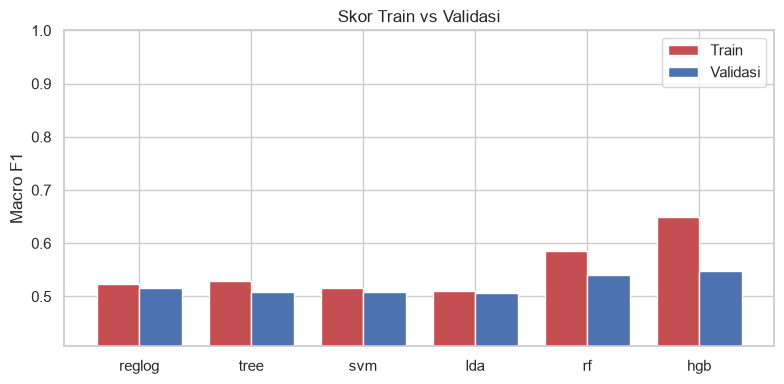

In [7]:
gap_rows = []
for m, model in fitted.items():
    g = fit_gap(model, X_tr, y_tr, X_va, y_va)
    gap_rows.append({"metode": m, **g})
gap_df = pd.DataFrame(gap_rows).set_index("metode")
display(gap_df)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(gap_df)); w = 0.38
ax.bar(x - w / 2, gap_df.train_f1, w, label="Train", color="#C44E52")
ax.bar(x + w / 2, gap_df.val_f1, w, label="Validasi", color="#4C72B0")
ax.set_xticks(x); ax.set_xticklabels(gap_df.index)
ax.set_ylim(max(0, gap_df.val_f1.min() - 0.1), 1.0)
ax.set(ylabel="Macro F1", title="Skor Train vs Validasi"); ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "train_vs_val.png", dpi=150)
plt.show()

### Kurva validasi

Skor train vs K-Fold CV terhadap parameter yang mengatur kompleksitas model (mis. `min_samples_leaf` pada pohon, `C` pada reglog). Titik dengan skor CV tertinggi adalah yang terbaik; ke arah model lebih sederhana cenderung underfit, ke arah lebih kompleks cenderung overfit.

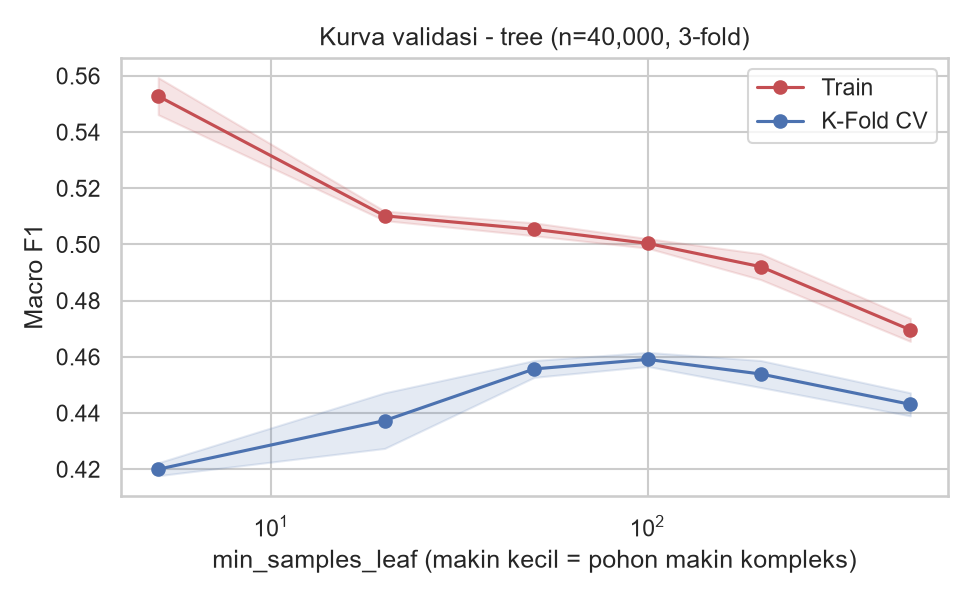

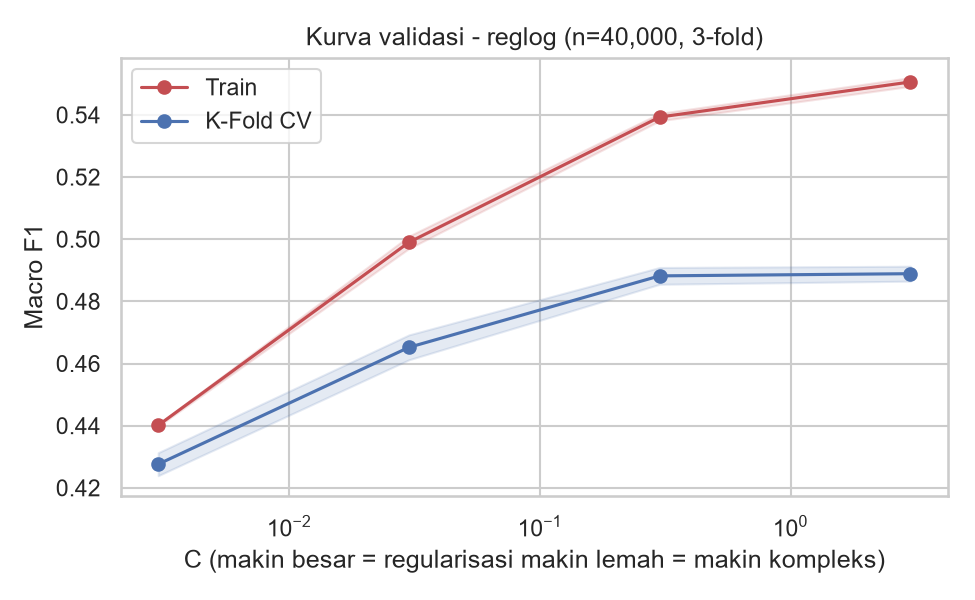

In [8]:
from scripts.evaluation import validation_curve_report
from IPython.display import Image, display as show

for m in CURVE_METHODS:
    if RUN_CURVES:
        validation_curve_report(m, n=CURVE_N, cv=3)
    f = FIG_DIR / f"validation_curve_{m}.png"
    if f.exists():
        show(Image(filename=str(f)))

## 6. Perbandingan metode

In [9]:
comp = pd.DataFrame(results).T["macro_f1"].sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(comp.index, comp.values, color="#4C72B0")
for i, v in enumerate(comp.values):
    ax.text(v + 0.0015, i, f"{v:.4f}", va="center")
ax.set_xlim(comp.min() - 0.03, comp.max() + 0.02)
ax.set(title="Macro F1 pada data validasi", xlabel="Macro F1")
fig.tight_layout()
fig.savefig(FIG_DIR / "model_comparison.png", dpi=150)
plt.show()

## 7. Penyesuaian bobot kelas untuk Macro F1

Macro F1 memperlakukan semua kelas setara. Skor tiap kelas dikalikan pengali (atau ditambah offset untuk SVM) yang dicari di validasi. Kolom *estimasi_gain_jujur* dihitung dengan membagi validasi dua (cari di separuh, uji di separuh lain) sehingga tidak terlalu optimistis.

In [10]:
rw = []
for m, model in fitted.items():
    scores, additive = get_scores(model, X_va)
    w = optimize_class_weights(scores, y_va, model.classes_, additive)
    gain = honest_reweight_gain(scores, y_va, model.classes_, additive)
    adj = scores + w if additive else scores * w
    f1_w = f1_score(y_va, model.classes_[adj.argmax(1)], average="macro")
    rw.append({"metode": m, "f1_tanpa": results[m]["macro_f1"],
               "f1_dengan_penyesuaian(optimistis)": f1_w, "estimasi_gain_jujur": gain})
display(pd.DataFrame(rw).round(4))

,metode,f1_tanpa,f1_dengan_penyesuaian(optimistis),estimasi_gain_jujur
0,reglog,0.5166,0.5220,0.0047
1,tree,0.5088,0.5182,0.0094
2,svm,0.5088,0.5175,0.0076
3,lda,0.5060,0.5081,0.0014
4,rf,0.5395,0.5493,0.0086
5,hgb,0.5483,0.5546,0.0057


## 8. Model selection: Grid Search vs Random Search

Hasil dari `python -m scripts.model_selection --model <nama>` (pencarian dilakukan pada subsampel stratified, scoring `f1_macro`, StratifiedKFold).

In [11]:
rows = []
for m in CORE_METHODS:
    p = ROOT / "reports" / f"model_selection_{m}.json"
    if p.exists():
        r = json.loads(p.read_text())
        rows.append({"metode": m, "n_data": r["tune_size"], "cv": r["cv"],
                     "baseline": r["baseline"]["cv_f1_macro"],
                     "grid": r["grid_search"]["best_cv_f1_macro"], "grid_detik": r["grid_search"]["seconds"],
                     "random": r["random_search"]["best_cv_f1_macro"], "random_detik": r["random_search"]["seconds"],
                     "param_terpilih": r["best_params"]})
if rows:
    display(pd.DataFrame(rows))
else:
    print("Belum ada hasil. Jalankan: python -m scripts.model_selection --model reglog")

,metode,n_data,cv,baseline,grid,grid_detik,random,random_detik,param_terpilih
0,reglog,40000,5,0.4943,0.4943,180.1,0.4935,87.6,{'algo__C': 1.0}
1,tree,100000,5,0.4765,0.4812,572.2,0.4812,300.3,"{'algo__criterion': 'entropy', 'algo__max_dept..."
2,svm,30000,3,0.4728,0.4743,63.0,0.4743,41.5,{'algo__C': 0.3}
3,lda,100000,5,0.5009,0.5009,66.9,0.5003,35.6,{'algo__solver': 'svd'}


## 9. Fitur yang paling berpengaruh (Random Forest)

*Catatan:* importance berbasis impurity cenderung menguntungkan fitur dengan banyak nilai unik (mis. kode wilayah), jadi baca sebagai indikasi kasar.

In [12]:
if "rf" in fitted:
    from scripts.preprocess import CATEGORICAL_COLS, NUMERIC_COLS, GEO_COLS
    imp = fitted["rf"].named_steps["algo"].feature_importances_
    names = (CATEGORICAL_COLS + NUMERIC_COLS + GEO_COLS
             + [f"TE_wilayah_{i}" for i in range(10)] + [f"agregat_wilayah_{i}" for i in range(13)])
    assert len(names) == len(imp), (len(names), len(imp))
    s = pd.Series(imp, index=names)
    group = {
        "kategorikal": s[CATEGORICAL_COLS].sum(),
        "numerik": s[NUMERIC_COLS].sum(),
        "kode wilayah mentah": s[GEO_COLS].sum(),
        "target-encoding wilayah": s[[n for n in names if n.startswith("TE_")]].sum(),
        "agregat wilayah": s[[n for n in names if n.startswith("agregat_")]].sum(),
    }
    top = s[CATEGORICAL_COLS + NUMERIC_COLS + GEO_COLS].sort_values().tail(10)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    pd.Series(group).sort_values().plot(kind="barh", ax=axes[0], color="#DD8452")
    axes[0].set_title("Importance per kelompok fitur")
    top.plot(kind="barh", ax=axes[1], color="#4C72B0")
    axes[1].set_title("10 fitur tunggal teratas (tanpa TE/agregat)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "feature_importance_rf.png", dpi=150)
    plt.show()

## 10. Ringkasan training final (hasil `scripts.train`)

In [13]:
rows = []
for m in CORE_METHODS + EXTRA_METHODS:
    p = ROOT / "reports" / f"train_summary_{m}.json"
    if p.exists():
        r = json.loads(p.read_text())
        adj = r.get("class_adjustment", {})
        rows.append({"metode": m, "val_f1": r["val_f1_macro"],
                     "train_f1": r["fit_diagnostics"]["train_f1"],
                     "gap": r["fit_diagnostics"]["gap"],
                     "estimasi_gain_penyesuaian": adj.get("honest_gain"),
                     "detik": r["train_seconds"]})
if rows:
    display(pd.DataFrame(rows).set_index("metode"))
else:
    print("Belum ada. Jalankan: python -m scripts.train --model reglog --reweight")

,val_f1,train_f1,gap,estimasi_gain_penyesuaian,detik
metode,,,,,
reglog,0.5163,0.5241,0.0078,0.0056,188.4
tree,0.5088,0.5300,0.0212,0.0094,81.3
svm,0.5093,0.5171,0.0077,0.0073,686.4
lda,0.5060,0.5109,0.0049,0.0014,27.7
rf,0.5395,0.5861,0.0467,0.0086,91.4
hgb,0.5483,0.6485,0.1002,0.0057,176.3


## Catatan untuk interpretasi (isi dengan analisismu)

- Metode mana yang terbaik pada validasi, dan kenapa (asumsi model vs karakter data)?
- Kelas mana yang paling sulit diprediksi (lihat confusion matrix)?
- Apakah selisih antar-metode lebih besar daripada simpangan baku K-Fold?
- Bagaimana Grid Search dibanding Random Search (skor vs waktu)?
- Fitur/kelompok fitur apa yang paling berpengaruh?
- Apakah ada model yang overfit (gap besar) atau underfit (skor rendah, gap kecil)? Apa buktinya (tabel Train vs Validasi dan kurva validasi)?